# Module 6. Decision Trees and Ensemble Learning

## 6.1 - Project Overview: Credit Risk Scoring

### Problem overview

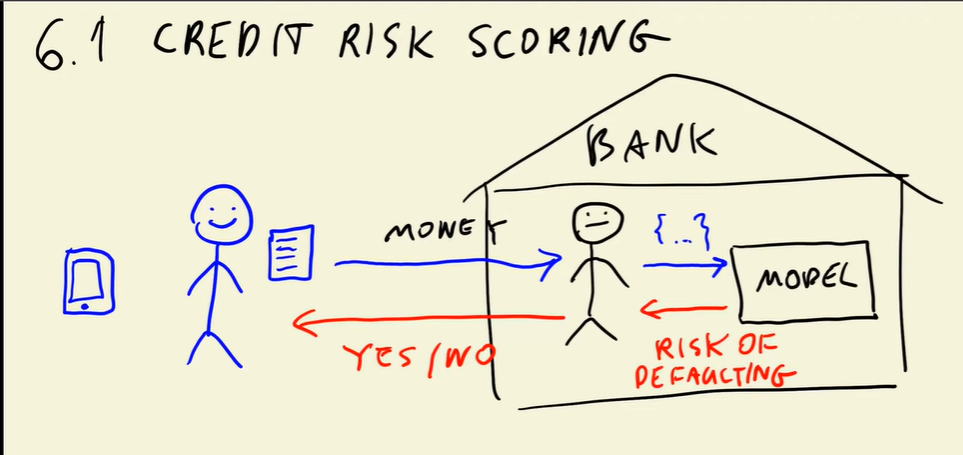

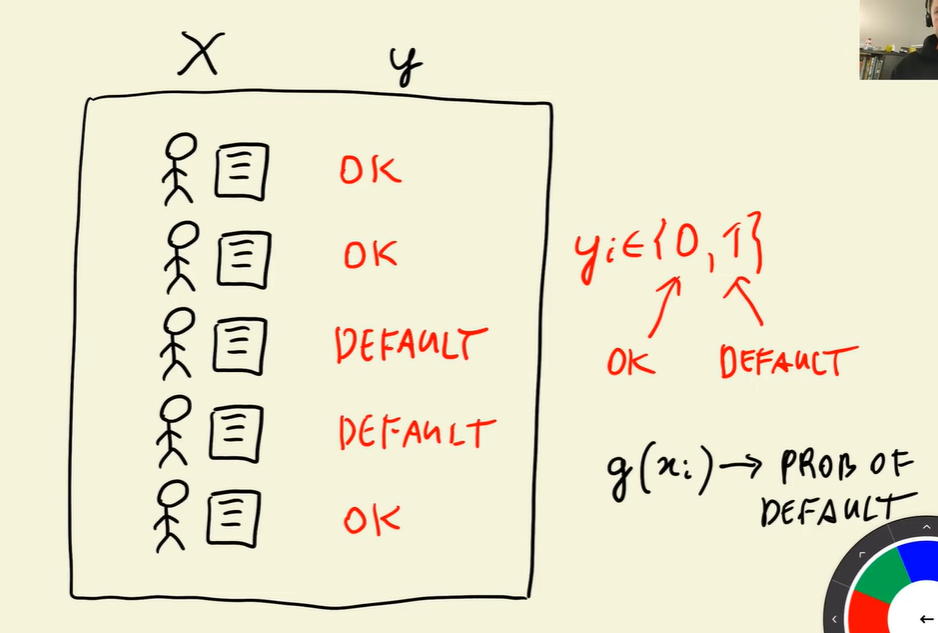

### Dataset

The raw dataset is in the file **"CreditScoring.csv"** which contains 4455 rows and 14 columns:

| # | Column | Description |
|---|--------|-------------|
| 1 | Status | credit status |
| 2 | Seniority | job seniority (years) |
| 3 | Home | type of home ownership |
| 4 | Time | time of requested loan |
| 5 | Age | client's age |
| 6 | Marital | marital status |
| 7 | Records | existence of records |
| 8 | Job | type of job |
| 9 | Expenses | amount of expenses |
| 10 | Income | amount of income |
| 11 | Assets | amount of assets |
| 12 | Debt | amount of debt |
| 13 | Amount | amount requested of loan |
| 14 | Price | price of good |


## 6.2 - Data Cleaning and Preparation

### Get the dataset

In [1]:
import os
import urllib.request

import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'
filename = 'CreditScoring.csv'

# only download if we don't already have the file
if not os.path.exists(filename):
    urllib.request.urlretrieve(data, filename)

In [3]:
df = pd.read_csv('CreditScoring.csv')

df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


### Transform the data

Standardizing column names

In [4]:
df.columns = df.columns.str.lower()

df.columns

Index(['status', 'seniority', 'home', 'time', 'age', 'marital', 'records',
       'job', 'expenses', 'income', 'assets', 'debt', 'amount', 'price'],
      dtype='str')

Re-encoding the categorical variables


In [5]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

In [6]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

df.status.value_counts()

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

In [7]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

df.home.value_counts()

home
owner      2107
rent        973
parents     783
other       319
private     247
ignore       20
unk           6
Name: count, dtype: int64

In [8]:
marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

df.marital.value_counts()

marital
married      3241
single        978
separated     130
widow          67
divorced       38
unk             1
Name: count, dtype: int64

In [9]:
records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

df.records.value_counts()

records
no     3682
yes     773
Name: count, dtype: int64

In [10]:
job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

df.job.value_counts()

job
fixed        2806
freelance    1024
partime       452
others        171
unk             2
Name: count, dtype: int64

In [11]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


### Descriptive stats to find missing values

In [12]:
df.describe()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.000000,4455.000000,4455.000000,4455.000000,4.455000e+03,4.455000e+03,4.455000e+03,4455.000000,4455.000000
mean,7.987205,46.441751,37.077666,55.568799,7.633170e+05,1.060341e+06,4.043820e+05,1039.021773,1462.875645
std,8.173444,14.655225,10.984856,19.515878,8.703625e+06,1.021757e+07,6.344253e+06,474.543007,628.089913
min,0.000000,6.000000,18.000000,35.000000,0.000000e+00,0.000000e+00,0.000000e+00,100.000000,105.000000
25%,2.000000,36.000000,28.000000,35.000000,8.000000e+01,0.000000e+00,0.000000e+00,700.000000,1117.500000
50%,5.000000,48.000000,36.000000,51.000000,1.200000e+02,3.500000e+03,0.000000e+00,1000.000000,1400.000000
75%,12.000000,60.000000,45.000000,72.000000,1.660000e+02,6.000000e+03,0.000000e+00,1300.000000,1692.000000
max,48.000000,72.000000,68.000000,180.000000,1.000000e+08,1.000000e+08,1.000000e+08,5000.000000,11140.000000


The maximum values of income, assets and debt look suspicious: 99999999. This dataset encodes missing values as a long number of nines. Instead of NaN, "unknown" became 99999999.

In [13]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [14]:
df.describe()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.000000,4455.000000,4455.000000,4455.000000,4421.000000,4408.000000,4437.000000,4455.000000,4455.000000
mean,7.987205,46.441751,37.077666,55.568799,130.568197,5403.433984,342.948614,1039.021773,1462.875645
std,8.173444,14.655225,10.984856,19.515878,86.367434,11573.161523,1245.861736,474.543007,628.089913
min,0.000000,6.000000,18.000000,35.000000,0.000000,0.000000,0.000000,100.000000,105.000000
25%,2.000000,36.000000,28.000000,35.000000,80.000000,0.000000,0.000000,700.000000,1117.500000
50%,5.000000,48.000000,36.000000,51.000000,120.000000,3000.000000,0.000000,1000.000000,1400.000000
75%,12.000000,60.000000,45.000000,72.000000,165.000000,6000.000000,0.000000,1300.000000,1692.000000
max,48.000000,72.000000,68.000000,180.000000,959.000000,300000.000000,30000.000000,5000.000000,11140.000000


### Removing the one unknown status


In [15]:
df.status.value_counts()

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

In [16]:
df = df[df.status != 'unk'].reset_index(drop=True)

In [17]:
df.status.value_counts()

status
ok         3200
default    1254
Name: count, dtype: int64

### Train-val-test split

In [18]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)

print(df_full_train.shape)
print(df_test.shape)


(3563, 14)
(891, 14)


In [19]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

print(df_train.shape)
print(df_val.shape)

(2672, 14)
(891, 14)


In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Preparing the target variable

In [21]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(2672,)
(891,)
(891,)


In [22]:
del df_train['status']
del df_val['status']
del df_test['status']

### Inspect prepared datasets

In [23]:
df_train.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897


In [24]:
df_val.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,6,rent,36,31,separated,no,fixed,49,140.0,0.0,0.0,550,999
1,18,rent,60,38,married,no,fixed,56,108.0,0.0,0.0,1000,1307
2,17,rent,24,40,married,yes,fixed,58,128.0,0.0,0.0,700,982
3,2,other,48,29,married,no,fixed,75,96.0,6000.0,3000.0,1200,1521
4,25,rent,42,61,married,no,fixed,57,121.0,0.0,0.0,750,830


In [25]:
df_test.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,3,owner,36,26,single,no,freelance,35,0.0,60000.0,3000.0,800,1000
1,10,rent,60,28,married,no,fixed,78,325.0,18.0,3000.0,2250,2250
2,14,rent,60,41,married,no,fixed,53,181.0,0.0,0.0,1150,2497
3,4,owner,60,39,married,no,freelance,45,0.0,7500.0,0.0,1300,1508
4,1,other,30,20,single,no,fixed,35,90.0,0.0,0.0,450,500
